In [1]:
%pip install -r requirements-offline.txt --quiet

/home/coding/projects/datascience-metrology/.claude/worktrees/issue-32/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Exercise — Module M7: ทำงานอัตโนมัติ

**วิธีทำ:** เติมช่อง `# TODO` / `...` ให้ทุกเซลล์รันผ่าน แล้วตอบคำถาม markdown ที่กำหนด —
เปิด `book.ipynb` เทียบได้ตลอด (โค้ดชุดเดียวกัน แค่มีคำอธิบายมากกว่า)

**ข้อมูล (citation):** กรมควบคุมมลพิษ (2568), pcd.gdcatalog.go.th (Open Data Common)

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

DATA = repo_root() / "datasets"

pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
pm25["date"] = pd.to_datetime(pm25["observation_date"])

## ส่วนที่ 1 — เตรียมเทมเพลต (1 สถานี)

In [3]:
# TODO: สร้างคอลัมน์ month จาก date (เข้าถึงส่วนเดือนของวันที่)
pm25["month"] = ...

# TODO: สรุปสถานี 05T: mean และ max ของ measured_value รายเดือน
one = ...
summary = ...
summary.round(1).head(4)

AttributeError: 'ellipsis' object has no attribute 'round'

**คำถาม 1.1** สถานี 05T เดือนไหน max_pm25 สูงสุด — ค่าเฉลี่ยเดือนนั้น
สูงสุดด้วยหรือไม่? (ตัวอย่างที่ max สูงแต่ mean ไม่สูง = เหตุผลที่รายงาน
ต้องมีทั้งสองตัว)

## ส่วนที่ 2 — วนทุกสถานี เขียนไฟล์อัตโนมัติ

In [4]:
outputs = Path("outputs")
outputs.mkdir(exist_ok=True)

# TODO: วนทุกสถานี (for code, group in pm25.groupby("station_code"))
# สรุป mean/max รายเดือน แล้วเขียน outputs/station_<code>.csv
# (ใช้ groupby("month") + agg + to_csv — แบบ book §2)
...

Ellipsis

**คำถาม 2.1** ไฟล์ที่สร้างได้ 15 ไฟล์ — ถ้าวันหน้าได้ข้อมูล 100 สถานี
สคริปต์นี้ต้องแก้กี่จุด? สิ่งนี้บอกอะไรเรื่อง "งานที่พร้อมโต"?

## ส่วนที่ 3 — อ่านกลับมารวม

In [5]:
# TODO: อ่านไฟล์ station_*.csv ทั้งหมดจาก outputs/ มารวมเป็นตารางเดียว
# (glob + loop read_csv + เติมคอลัมน์ station + concat — แบบ book §3)
frames = []
for path in ...:
    ...
combined = ...

print(f"ได้ {len(combined):,} แถว × {combined.shape[1]} คอลัมน์")

TypeError: 'ellipsis' object is not iterable

**คำถาม 3.1** ตาราง `combined` มี 5,475 แถวเท่ากับ `pm25` พอดี —
เหตุใดการ "แตกไฟล์แล้วรวมกลับ" จึงไม่เสียแถวเพิ่มหรือหายไป?

## ส่วนที่ 4 — กราฟอัตโนมัติ

In [6]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

# TODO: วน 3 สถานี "50T", "53T", "61T" วาดกราฟรายวัน + savefig
# ชื่อไฟล์: outputs/chart_<code>.png (แบบ book §4)
...

Ellipsis

**คำถาม 4.1** สถานีทั้งสามมีจังหวะฤดูเดียวกันหรือไม่ — ถ้าเป้าหมายคือ
"แจ้งเตือนประชาชนก่อนฝุ่นพุ่ง" จะเลือกใช้ค่ารายวันดิบ หรือ moving average
(จาก M6) เป็นฐานแจ้งเตือน ทำไม?

## ส่วนที่ 5 — แบบฝึกปิดท้าย: reproduce a figure (30 นาที)

งานปิดคอร์ส: ย้อนกลับไปปี 1973 แล้วสร้างผลงานชิ้นโบว์แดงของสถิติขึ้นมาใหม่
ด้วยทักษะที่เรียนมาทั้งสองวัน — **Anscombe's quartet**: ข้อมูล 4 คู่ (x, y)
ที่ตัวเลขสรุปเหมือนกันแทบทุกตัว แต่กราฟต่างกันคนละเรื่อง

**ทำ 3 ขั้น (~30 นาที):** โหลดข้อมูล (~3 น.) → วาดระวาง 4 แผง (~12 น.) →
ตารางสถิติสรุป + ตรวจเอง (~10 น.) → ตอบคำถาม (~5 น.)

**หมายเหตุ (อ้างต้นฉบับให้ตรง):** ต้นฉบับปี 1973 พิมพ์ภาพ scatter เป็น
**4 รูปแยกจากกัน ไม่ใช่กริด 2×2** — การรวมเป็นระวางเดียวเป็นการเรียบเรียง
ใหม่ของยุคหลัง เวลาอ้างอิงจึงต้องบอกว่า "ตาม Anscombe (1973)
แต่รวมเป็นระวางเดียว"


**ข้อมูล + citation:** Anscombe, F. J. (1973). *Graphs in Statistical
Analysis*. The American Statistician, 27(1), 17–21.
DOI: 10.1080/00031305.1973.10478966 — ไฟล์ CSV คือตารางข้อมูลต้นฉบับ
`datasets/anscombe/anscombe_quartet.csv` (wide: 11 แถว × 8 คอลัมน์
`x1–x4, y1–y4` = 44 จุด)

**กระดาษคำตอบอยู่ในตัวกระดาษ** — ต้นฉบับพิมพ์สรุปของทั้ง 4 คู่ไว้แล้ว
และทุกคู่ได้ตัวเลขชุดเดียวกัน คุณจึงตรวจคำตอบตัวเองได้จากค่าที่พิมพ์
ในต้นฉบับ:

| ค่าที่ต้นฉบับพิมพ์ (ทุกคู่เท่ากัน) | |
|---|---|
| ค่าเฉลี่ย x | 9.0 |
| ค่าเฉลี่ย y | 7.5 |
| ความชัน (slope) | 0.5 |
| R² | 0.667 |

(เส้นตรงเทียบของทุกคู่: **y = 3.00 + 0.500x**)


In [7]:
# TODO: โหลด datasets/anscombe/anscombe_quartet.csv (M2 ก1 — Path จาก DATA)
anscombe = ...
print(f"{len(anscombe)} แถว × {len(anscombe.columns)} คอลัมน์ "
      "= 4 คู่ (x, y) × 11 จุด")
anscombe


TypeError: object of type 'ellipsis' has no len()

### ขั้นที่ 2 — วาดระวาง 4 แผง (~12 น.)

กริด 2×2 ด้วย `plt.subplots(2, 2)` (M4 ก6) — แต่ละแผงวาด 1 คู่: จุด
scatter (M4 ก1) + เส้น trend จาก `np.polyfit` (M6 ก2) วาดจากจุดปลาย x
ซ้ายไปขวา

โครงวนให้พร้อมแล้ว — วนคู่ (เลขคู่ i, แผงปลายทาง) ทีละคู่แบบ M4 ก2
แก้เฉพาะบรรทัดที่ติด `# TODO`:


TypeError: 'ellipsis' object is not subscriptable

findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


...

findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


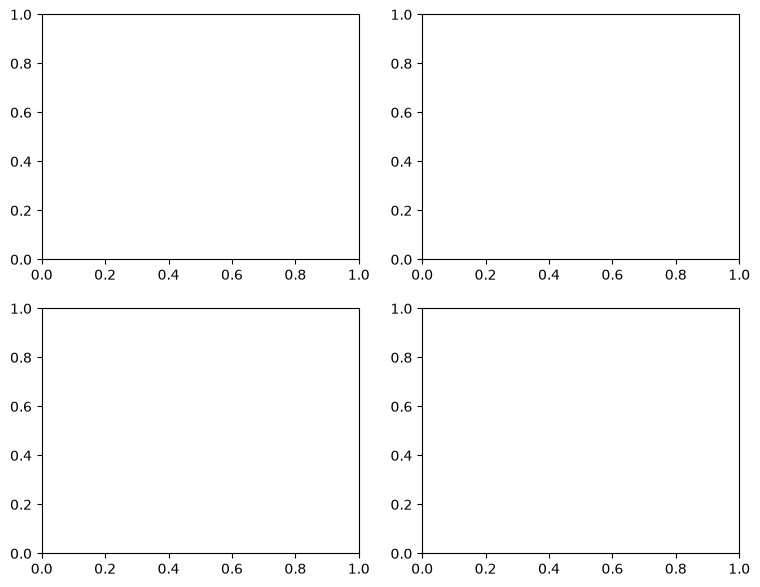

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for i, ax in [(1, axes[0][0]), (2, axes[0][1]),
              (3, axes[1][0]), (4, axes[1][1])]:
    x = anscombe[f"x{i}"]     # ชื่อคอลัมน์ต่อจากเลขคู่ (M1 f-string + M2)
    y = ...
    xs = np.array([x.min(), x.max()])   # จุดปลายสองข้างของเส้น trend

    # TODO: slope, intercept = np.polyfit(x, y, 1)   (M6 ก2)
    # TODO: ax.scatter(x, y, s=22, color="#457b9d")
    # TODO: ax.plot(xs, intercept + slope * xs, color="#e07a5f", lw=1.2)
    # TODO: ax.set_title(f"คู่ที่ {i}: y = {intercept:.2f} + {slope:.2f}x")
    #       + ป้ายแกน x{i} / y{i} (M4 ก5)


### ขั้นที่ 3 — ตารางสถิติสรุป + ตรวจเอง (~10 น.)

ต่อคู่: ค่าเฉลี่ย x, ค่าเฉลี่ย y (M5 ก2) · ความชัน = cov(x, y) ÷ var(x) ·
R² = r² เมื่อ r = cov(x, y) ÷ (sd(x) × sd(y)) — สูตร pandas ล้วน (`.cov()`
กับ `.var()` เป็นของใหม่ของโมดูลนี้ — ดู `function.md` กลุ่มที่ 6) แล้ววัด
กับค่าที่ต้นฉบับพิมพ์


In [9]:
rows = []
for i in [1, 2, 3, 4]:
    x = anscombe[f"x{i}"]
    y = anscombe[f"y{i}"]
    slope = x.cov(y) / x.var()             # ความชัน: cov ÷ var
    r = x.cov(y) / (x.std() * y.std())     # สหสัมพรรค์: cov ÷ (sd·sd)
    rows.append({
        "pair": i,
        "mean_x": ...,                     # TODO
        "mean_y": ...,                     # TODO
        "slope": slope,
        "r2": ...,                         # TODO: r ยกกำลังสอง (M1)
    })

stats = pd.DataFrame(rows).set_index("pair")
stats.round(3)


TypeError: 'ellipsis' object is not subscriptable

In [10]:
# ตรวจเอง (self-verifying) — ต่างจากที่ต้นฉบับพิมพ์ได้ไม่เกิน 0.001
expected = pd.DataFrame(
    {"mean_x": 9.0, "mean_y": 7.5, "slope": 0.5, "r2": 0.667},
    index=stats.index,
)
diff = (stats[["mean_x", "mean_y", "slope", "r2"]] - expected).abs()

ok = bool((diff < 0.001).all().all())
print("ผ่าน — ตารางของคุณตรงกับตัวเลขที่ต้นฉบับพิมพ์ทุกค่า" if ok
      else "ยังไม่ตรง — กลับไปเช็คขั้นที่ 3")


NameError: name 'stats' is not defined

**คำถาม 5.1** ตารางของคุณบอกว่าทั้งสี่คู่มีตัวเลขสรุปเหมือนกัน (ตรงกับที่
ต้นฉบับพิมพ์) แต่ระวาง 4 แผงที่วาดกลับคนละเรื่อง — บทเรียนนี้พูดกับงาน
วิเคราะห์ของคุณหลังจบคอร์สอย่างไร 1–2 ประโยค (เชื่อมกับคำถาม
"ทำไมจึงเชื่อ" ของ M6 ด้วย)
